# Class 1 — From CAPM to Multifactor Models
## Understanding factors, evaluating premiums, and analyzing companies

**Student’s notebook — exercises**

In the previous class, we found that the market explains only part of an individual stock's return fluctuations. Today, we ask whether other common factors help us understand companies, and whether those factors offer persistent return premiums.

**Learning path:** (1) Why multiple factors? → (2) Understanding size and value → (3) Historical factor premiums → (4) Historical stability → (5) Rolling evidence → (6) Momentum → (7) Company analysis and CAPM comparison → (8) Conclusions

Each section combines a short explanation, a programming task, and questions for financial interpretation. We use **stock log returns**; Fama–French long–short factor returns remain in their published simple-return convention (a clearly stated approximation when included in regressions with log returns).

## 1. Why move beyond CAPM?

The CAPM uses only market exposure. Yet two firms with similar market betas can react differently to interest rates, sector demand, or changes in growth expectations.

A **general multifactor return model** is:

$$
r_{i,t}-r_{f,t}=\alpha_i+\sum_{k=1}^{K}\beta_{i,k}f_{k,t}+\varepsilon_{i,t}.
$$

Here $f_{k,t}$ is a common factor and $\beta_{i,k}$ measures a stock's exposure to it. An exposure can improve the explanation of historical fluctuations without demonstrating that the factor is priced or that future returns can be forecast.


**Think:** How might a bank and an airline react differently to rising interest rates or energy prices?

### 1.1 What kinds of factors can affect stock returns?

**Theory.** The market is not the only source of common risk. Different companies respond to different economic shocks. For example, an oil-price increase may raise an airline's costs while benefiting an oil producer. Similarly, a change in interest rates can affect a bank and a real estate company in different ways.

| Factor family | Examples | Financial intuition |
|---|---|---|
| **Market** | Broad equity-market returns | Exposure to movements affecting the whole market |
| **Macroeconomic** | Interest rates, inflation, economic growth, oil-price shocks | Different businesses react differently to economic conditions |
| **Industry** | Technology, energy, banks | Companies in the same industry share business and regulatory risks |
| **Fundamental / style** | Size, value, profitability, investment | Stocks with similar characteristics may display common return patterns |
| **Price-based strategies** | Momentum | Recent winners and losers may have different subsequent returns |

A factor can **explain movements in returns** without necessarily earning a **positive risk premium**. And not every empirical return pattern is automatically a priced source of risk.

**Think (no coding yet).** Which factors would matter most for (a) an airline, (b) an oil producer, and (c) a regional bank? Could two stocks have similar market betas but different exposures to these other factors?

**Our focus today:** Rather than estimating every possible factor, we will study the observable **size, value, and momentum** factor portfolios and ask whether their historical return spreads are economically meaningful and stable. Later in this notebook, we will use factor regressions to analyze individual stocks; the next class will focus on investment funds.


## 2. Understanding size and value factors

**Size:** market capitalization is stock price multiplied by shares outstanding. **Value vs. growth:** a company's book-to-market ratio is its accounting equity relative to its market capitalization:

$$
B/M=\frac{\text{Book equity}}{\text{Market capitalization}}=\frac{1}{P/B}.
$$

Companies with high $B/M$ are conventionally labelled **value**; companies with low $B/M$ are labelled **growth**. These are *relative valuation categories*, not industry classifications. Accounting for intangible investment can also influence $B/M$.

In the original Fama–French three-factor construction, firms are sorted into **Small/Big** and **Low/Neutral/High $B/M$** portfolios. Two return spreads capture these patterns:

$$
SMB_t=\frac{SG_t+SN_t+SV_t}{3}-\frac{BG_t+BN_t+BV_t}{3}
$$

$$
HML_t=\frac{SV_t+BV_t}{2}-\frac{SG_t+BG_t}{2}
$$

Each underlying portfolio is value-weighted; the portfolio sorts use NYSE size and $B/M$ breakpoints. A positive HML realization means that the **value side outperformed the growth side** that month, not that every value company performed better.

**Task:** Explain why Fama–French sorts by both size and $B/M$ rather than comparing all value companies with all growth companies. What does a negative SMB return mean?

### 2.1 Load the monthly Fama–French data

We use the **monthly factor CSV already used in the original course notebook** (`APT.ipynb`). This avoids relying on the Dartmouth server for the main exercises.

The file stores returns in **percent**; divide by 100. We keep the factors in their **published simple-return convention**. In the historical analysis, we study the published factor spreads. In the company exercise at the end of this notebook, we use monthly stock log returns.

**Task:** Import the data, inspect the first observations, and verify the factor names and units.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf

In [16]:
# Monthly factors from the original course repository
url = ('https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/refs/heads/Finance_Technology/Tema_5_APT/data/F-F_Research_Data_Factors_monthly.csv')

#url = "../data/F-F_Research_Data_Factors_monthly.csv"

factors = pd.read_csv(url, index_col=0) / 100

# Convert YYYYMM into dates
factors.index = pd.to_datetime(factors.index.astype(str), format='%Y%m')

factors = factors.sort_index()

display(factors.head())
print('Sample:', factors.index.min().date(), 'to', factors.index.max().date())

,Mkt-RF,SMB,HML,RF
1926-07-01,0.0289,-0.0242,-0.0275,0.0022
1926-08-01,0.0264,-0.0144,0.0413,0.0025
1926-09-01,0.0038,-0.0136,0.0005,0.0023
1926-10-01,-0.0327,-0.0018,0.0078,0.0032
1926-11-01,0.0254,-0.0017,-0.0048,0.0031


Sample: 1926-07-01 to 2026-09-01


### 2.2 Visualize factor realizations

**Task:** Plot monthly returns for SMB and HML, then compute the **cumulative return spread** using a cumulative sum. Use a cumulative **sum** because we are illustrating a spread over time, not constructing an investor's compounded wealth.

**Interpretation:** Identify periods where small stocks outperformed large stocks, and value stocks outperformed growth stocks. Do the spreads always have the same sign?

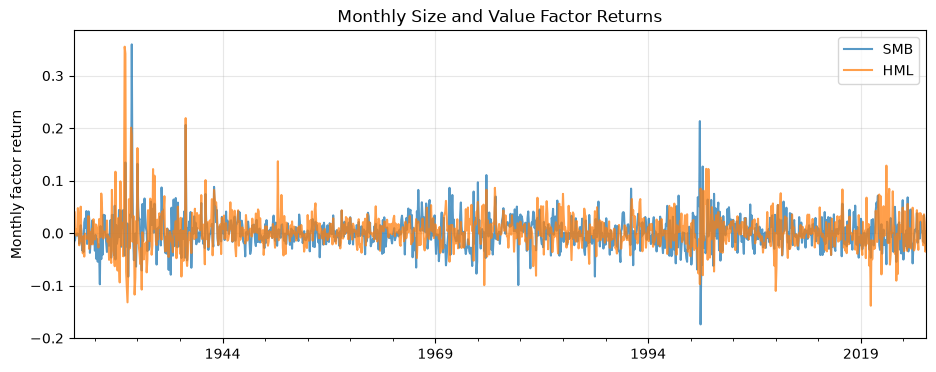

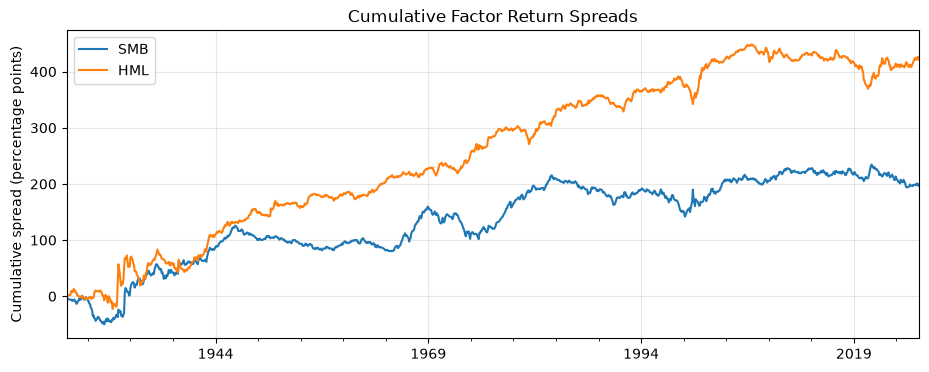

In [2]:
# Monthly factor returns
factors[['SMB', 'HML']].plot(figsize=(11, 4), alpha=0.75)
plt.title('Monthly Size and Value Factor Returns')
plt.ylabel('Monthly factor return')
plt.grid(alpha=0.3)
plt.show()

# Add up monthly return spreads (not portfolio wealth)
(100 * factors[['SMB', 'HML']].cumsum()).plot(figsize=(11, 4))
plt.title('Cumulative Factor Return Spreads')
plt.ylabel('Cumulative spread (percentage points)')
plt.grid(alpha=0.3)
plt.show()

## 3. Do size and value deliver positive premiums?

A factor may have a **positive historical average return**, but that average can be small relative to its fluctuations. We should report both economic magnitude and statistical uncertainty.

For monthly factor returns $f_t$:

$$\text{Annualized mean (arithmetic)}=12\overline{f},\qquad
\text{Annualized volatility}=\sqrt{12}\,s_f.$$

For a long–short factor, $\overline{f}/s_f\sqrt{12}$ is a **mean-to-volatility ratio**; interpreting it as a realized investment Sharpe ratio requires financing and implementation assumptions.

**Task:** Calculate these three summary statistics for market, SMB, and HML. Which has the largest average premium? Which has the most variable returns?

In [3]:
# Summary statistics for monthly factor premiums
factor_names = ['Mkt-RF', 'SMB', 'HML']

stats = pd.DataFrame({
    'Annualized mean': factors[factor_names].mean() * 12,
    'Annualized volatility': factors[factor_names].std() * np.sqrt(12),
    'Mean / volatility': factors[factor_names].mean() / factors[factor_names].std() * np.sqrt(12)
})

display(stats.round(3))

,Annualized mean,Annualized volatility,Mean / volatility
Mkt-RF,0.083,0.184,0.454
SMB,0.020,0.109,0.180
HML,0.042,0.123,0.342


### 3.1 Is the mean premium statistically different from zero?

Test $H_0: E[f_t]=0$ using a regression on a constant:

$$f_t=\mu+u_t.$$

Monthly financial returns can display heteroskedasticity and serial dependence. Use **Newey–West / HAC standard errors**, with 12 monthly lags, for the mean-premium t-statistic. This choice is a practical convention, not an exact solution to every dependence problem.

**Task:** Report the estimated annualized mean, t-statistic and p-value for each factor. Is a positive sample mean necessarily significant?

In [4]:
# Test whether each historical factor premium has a nonzero mean
results = []

for factor in factor_names:
    series = factors[factor].dropna()
    model = sm.OLS(series, np.ones(len(series))).fit(
        cov_type='HAC', cov_kwds={'maxlags': 12}
    )
    results.append([factor, 12 * model.params.iloc[0],
                    model.tvalues.iloc[0], model.pvalues.iloc[0]])

premium_tests = pd.DataFrame(
    results, columns=['Factor', 'Annualized Mean', 'HAC t-stat', 'p-value']
).set_index('Factor')

display(premium_tests.round(4))

,Annualized Mean,HAC t-stat,p-value
Factor,,,
Mkt-RF,0.0833,4.2450,0.0000
SMB,0.0196,1.6617,0.0966
HML,0.0420,3.0077,0.0026


**Financial interpretation (discuss after running the code).**

A statistically significant historical premium indicates evidence for a nonzero *sample-period mean*. It does not establish that the premium compensates a unique priced risk, nor that a profitable strategy would survive trading costs and future changes in market conditions.

**Question:** Why might a factor have a large annualized mean but still fail a statistical significance test?

## 4. Have the premiums remained stable?

Asset-pricing research has documented that factor performance varies across long periods. A risk exposure can be economically meaningful even when the associated **realized premium** is weak or negative in a particular decade.

To see this, compare the same factor across different historical windows. We will use the **1980 split for SMB** and the **2008 split for HML**.



### Task. Have Size and Value Premiums Remained Stable Over Time?

We have observed that SMB and HML have generated positive average returns over the full historical sample. But **have these premiums remained positive and statistically significant throughout history?**

Analyze the evolution of the two factors using the following subperiods:

- **SMB:** before 1980 vs. from 1980 onward.
- **HML:** before 2008 vs. from 2008 onward.

For each subperiod:

1. Calculate the number of months, **annualized mean return**, and **annualized volatility**.
2. Create a bar chart comparing the average annualized premiums across subperiods.
3. Plot the **cumulative sum of monthly factor returns**, showing the two subperiods in different colors for each factor.

**Financial interpretation:** Have SMB and HML delivered consistently positive premiums? When did their performance weaken? Are the average premiums statistically significant in both subperiods? What economic explanations might account for these differences?

*Note:* The subperiods are selected retrospectively. Positive historical factor premiums do not guarantee positive future returns.

In [17]:
# TO DO: 

## 5. Rolling factor premiums: can a historical average be trusted?

A single full-sample mean may conceal long periods when a factor does poorly. We now compare **rolling annualized premiums over 1, 5, and 10 years**.



### Task. Does the Investment Horizon Matter for Factor Premiums?

We have seen that SMB and HML have generated positive historical premiums, but these premiums are not stable over time. **Does a longer investment horizon make it more likely to obtain a positive factor premium?**

Using the monthly SMB and HML data:

1. Calculate the **rolling average annualized factor returns** over three investment horizons: **1 year (12 months), 5 years (60 months), and 10 years (120 months)**.
2. Create three separate plots, one for each horizon, showing the evolution of SMB and HML premiums.
3. Compare how the magnitude and variability of the estimated premiums change as the horizon increases.

**Financial interpretation:** Are negative factor premiums more common over shorter horizons? Do longer horizons produce more stable results? Can investors assume that factor premiums will be positive if they invest for ten years?

*Note:* Rolling historical averages describe past factor performance. They do not guarantee future returns or represent the realized performance of a conventional investment portfolio.

In [18]:
# TO DO

### 5.1 Rolling statistical evidence

The rolling mean indicates *magnitude*, but not precision. A moving estimate can be positive and still very uncertain.

**Task:** Calculate a rolling 120-month t-statistic for SMB and HML using the same HAC method. Draw reference lines at $+2$ and $-2$. These are only approximate guides, not multiple-testing-adjusted significance thresholds.

**Interpretation:** Does evidence for each factor remain strong throughout history? Why is repeated testing across overlapping windows not the same as an independent sequence of experiments?

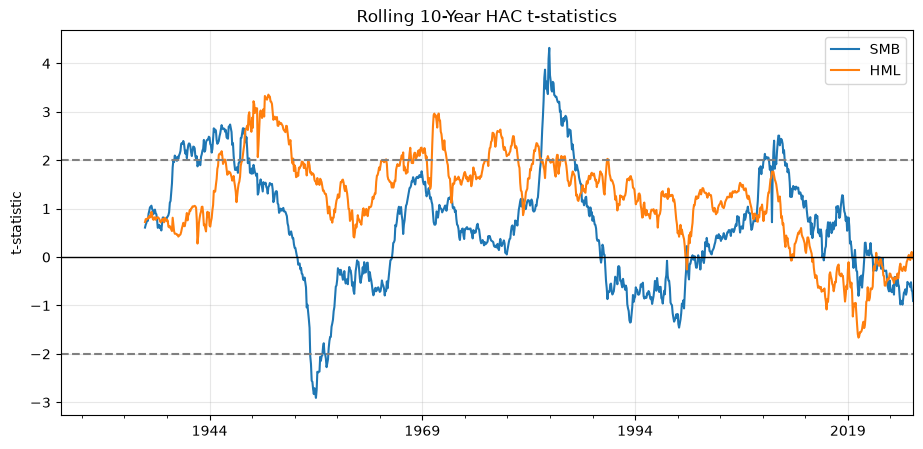

In [10]:
# Rolling HAC t-statistics for the historical mean
rolling_t = pd.DataFrame(index=factors.index)

for factor in ['SMB', 'HML']:
    t_values = []
    for end in range(120, len(factors) + 1):
        window = factors[factor].iloc[end - 120:end].dropna()
        reg = sm.OLS(window, np.ones(len(window))).fit(
            cov_type='HAC', cov_kwds={'maxlags': 12}
        )
        t_values.append(reg.tvalues.iloc[0])

    rolling_t[factor] = pd.Series(t_values, index=factors.index[119:])

ax = rolling_t.plot(figsize=(11, 5))
ax.axhline(2, color='gray', linestyle='--')
ax.axhline(-2, color='gray', linestyle='--')
ax.axhline(0, color='black', linewidth=1)
ax.set(title='Rolling 10-Year HAC t-statistics', ylabel='t-statistic')
ax.grid(alpha=0.3)
plt.show()

## 6. Momentum: does recent performance continue?

**Momentum** compares stocks that performed well in the recent past (*winners*) with those that performed poorly (*losers*). It is distinct from SMB and HML and is not included in the original three-factor model.

The course notebook `APT_analisis.ipynb` uses the **monthly Kenneth French Momentum Factor**. This is an **optional extension** if the CSV is available. Because the official Dartmouth server has sometimes been inaccessible, this section allows the instructor to use a **locally downloaded original CSV** (`F-F_Momentum_Factor.csv`). Download it separately from the [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) when the server is available.

**Task:** Load the monthly momentum series and compare its full-sample premium with SMB and HML. Use the cleaned monthly CSV, which contains only `YYYYMM` observations, as in the preceding exercises.

In [11]:
#url = "../data/F-F_Momentum_Factor.csv"

url = 'https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/refs/heads/Finance_Technology/Tema_5_APT/data/F-F_Momentum_Factor.csv'

mom = pd.read_csv(url, index_col=0) / 100

# Convert YYYYMM into dates
mom.index = pd.to_datetime(mom.index.astype(str), format='%Y%m')

mom = mom.sort_index()


In [12]:
# Combine Fama-French factors with Momentum
all_factors = factors.join(mom, how='inner')

# Display the combined factors
display(all_factors[['SMB', 'HML', 'Mom']].head())

,SMB,HML,Mom
1927-01-01,-0.0047,0.0476,0.0057
1927-02-01,-0.0023,0.0304,-0.0151
1927-03-01,-0.0201,-0.0232,0.0352
1927-04-01,0.0054,0.0062,0.0435
1927-05-01,0.0149,0.0504,0.0278


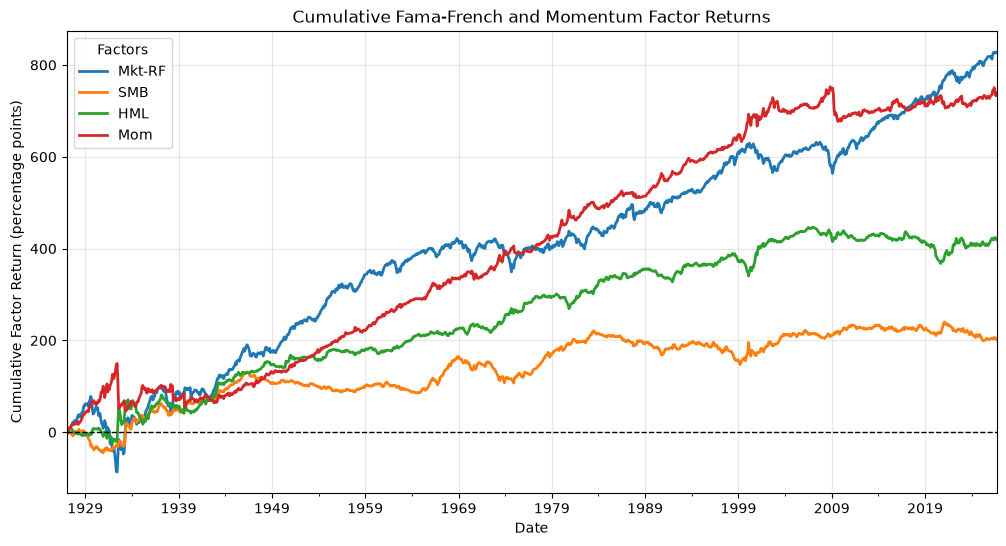

In [13]:
# Cumulative factor returns (in percentage points)
cumulative_factors = all_factors[['Mkt-RF', 'SMB', 'HML', 'Mom']].cumsum() * 100

ax = cumulative_factors.plot(figsize=(12, 6), linewidth=2)

ax.set(
    title='Cumulative Fama-French and Momentum Factor Returns',
    xlabel='Date',
    ylabel='Cumulative Factor Return (percentage points)'
)

ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.grid(alpha=0.3)
ax.legend(title='Factors')

plt.show()

### 6.1 Is momentum a stable premium?

I
**Task:** Calculate its annualized mean, volatility and HAC p-value **before and since June 2009**. Find its worst monthly return. Then compare its rolling average with SMB and HML.

**Financial question:** If a factor has a positive long-run average but occasionally suffers severe losses, what risks would an investor face when allocating capital to it?

In [21]:
# Momentum: compare before and after June 2009
mom_periods = {
    'Before Jun 2009': mom.loc[:'2009-05', 'Mom'],
    'Since Jun 2009': mom.loc['2009-06':, 'Mom']
}

rows = []
for name, series in mom_periods.items():
    reg = sm.OLS(series, np.ones(len(series))).fit(
        cov_type='HAC', cov_kwds={'maxlags': 12}
    )
    rows.append([name, 12 * series.mean(),
                 np.sqrt(12) * series.std(), reg.pvalues.iloc[0]])

mom_stats = pd.DataFrame(
    rows, columns=['Period', 'Annualized Mean', 'Annualized Volatility', 'HAC p-value']
).set_index('Period')

display(mom_stats.round(4))

print('Worst momentum month:', mom['Mom'].idxmin().date(),
      '| return:', round(mom['Mom'].min(), 4))



,Annualized Mean,Annualized Volatility,HAC p-value
Period,,,
Before Jun 2009,0.0838,0.1686,0.000
Since Jun 2009,0.0280,0.1304,0.224


Worst momentum month: 1932-08-01 | return: -0.5261


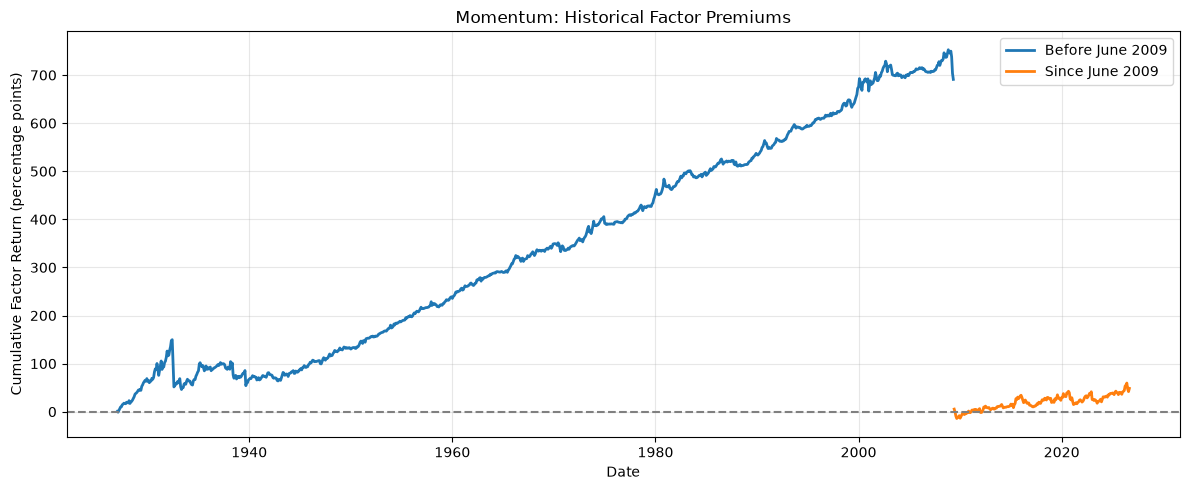

In [19]:
# Compare cumulative Momentum returns before and after June 2009
before = mom.loc[:'2009-05', 'Mom'].dropna().cumsum()
after = mom.loc['2009-06':, 'Mom'].dropna().cumsum()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(before.index, before * 100,
        color='tab:blue', linewidth=2, label='Before June 2009')

ax.plot(after.index, after * 100,
        color='tab:orange', linewidth=2, label='Since June 2009')

ax.axhline(0, color='gray', linestyle='--')
ax.set(
    title='Momentum: Historical Factor Premiums',
    ylabel='Cumulative Factor Return (percentage points)',
    xlabel='Date'
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

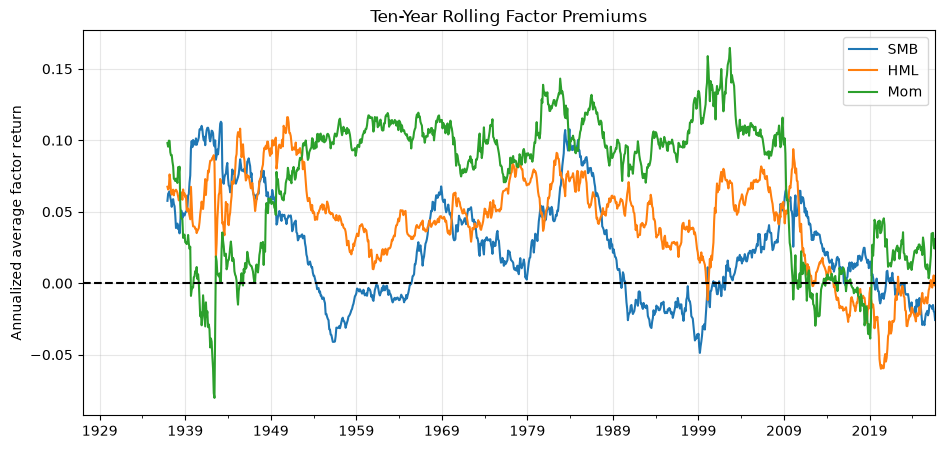

In [20]:
rolling_all = all_factors[['SMB', 'HML', 'Mom']].rolling(120).mean() * 12
ax = rolling_all.plot(figsize=(11, 5))
ax.axhline(0, color='black', linestyle='--')
ax.set(title='Ten-Year Rolling Factor Premiums', ylabel='Annualized average factor return')
ax.grid(alpha=0.3)
plt.show()

## 7. Can Fama–French factors describe real companies?

**Central task:** Estimate factor exposures for **Microsoft (MSFT), IBM, JPMorgan (JPM), Exxon Mobil (XOM), Walmart (WMT), and Monster Beverage (MNST)** and relate them to each company's business and accounting characteristics.

Before running any regression, formulate hypotheses: Which businesses look more *growth-like* or *value-like*? Which might behave like large firms or smaller growth firms?

| Company | Business characteristic to investigate |
|---|---|
| MSFT | Software, cloud services, high intangible investment |
| IBM | Established enterprise technology business |
| JPM | Banking and financial intermediation |
| XOM | Capital-intensive energy business |
| WMT | Large-scale retail distribution |
| MNST | Beverage business with strong historical growth |

These are **economic hypotheses**, not predetermined regression signs. A firm can have a low $B/M$ but a positive HML loading; return-based factor exposures are not identical to accounting categories.

### 7.1. Company size and book-to-market from Yahoo Finance

**Task:** Download the **current** market capitalization and price-to-book ratio ($P/B$) for each company. Calculate $B/M=1/(P/B)$, rank the firms, and discuss which appear more value-like or growth-like.

**Important:** Yahoo's current $P/B$ and market capitalization are a **snapshot**, not the historical characteristics for the regression period (2015–2024). Treat the comparison with historical exposures as illustrative, not a point-in-time test.

In [23]:
stocks = ['MSFT', 'IBM', 'JPM', 'XOM', 'WMT', 'MNST']
rows = []

for stock in stocks:
    info = yf.Ticker(stock).info
    rows.append([stock, info.get('marketCap'), info.get('priceToBook')])

company_data = pd.DataFrame(rows, columns=['Stock', 'Market Cap', 'P/B']).set_index('Stock')
company_data['Market Cap ($bn)'] = company_data['Market Cap'] / 1e9
company_data['B/M'] = 1 / company_data['P/B']

display(company_data[['Market Cap ($bn)', 'P/B', 'B/M']].sort_values('B/M', ascending=False).round(3))

,Market Cap ($bn),P/B,B/M
Stock,,,
JPM,860.710,2.450,0.408
XOM,655.042,2.465,0.406
IBM,215.988,6.078,0.165
MSFT,3774.660,8.023,0.125
MNST,87.912,8.934,0.112
WMT,1010.442,10.297,0.097


### 7.2. Estimate the Market Model and FF3 for each company

For comparison, estimate the one-factor Market Model and the Fama–French three-factor model:

$$
r_{i,t}^{e}=\alpha_i+\beta_{i,M}(Mkt-RF)_t+\varepsilon_{i,t}
$$

$$
r_{i,t}^{e}=\alpha_i+\beta_{i,M}(Mkt-RF)_t+s_iSMB_t+h_iHML_t+\varepsilon_{i,t}
$$

**Task:** Download adjusted prices for 2015–2024, compute **monthly log returns**, align months with FF3 data, and estimate both regressions for each company. Report factor coefficients, p-values, alpha, and adjusted $R^2$.

We use $\ln(1+RF)$ to convert the published risk-free simple return to a log return. **The FF factor returns remain simple-return spreads**, so the combined regression is a practical teaching approximation; it is not an exact log-return factor identity.

In [ ]:
# Download and compute monthly stock log returns
prices = yf.download(stocks, start='2014-12-01', end='2025-01-01',
                     auto_adjust=True, progress=False)['Close']

monthly_returns = np.log(prices.resample('ME').last()).diff()
monthly_returns.index = monthly_returns.index.to_period('M')

# Align monthly observations with the Fama-French data
ff = factors[['Mkt-RF', 'SMB', 'HML', 'RF']].copy()
ff.index = ff.index.to_period('M')
data = monthly_returns.join(ff, how='inner').loc['2015-01':'2024-12'].dropna()

# Convert monthly RF to log returns and calculate stock excess log returns
excess_stocks = data[stocks].sub(np.log1p(data['RF']), axis=0)


In [ ]:
# Download and compute monthly stock log returns
prices = yf.download(stocks, start='2014-12-01', end='2025-01-01',
                     auto_adjust=True, progress=False)['Close']

monthly_returns = np.log(prices.resample('ME').last()).diff()
monthly_returns.index = monthly_returns.index.to_period('M')

# Align monthly observations with the Fama-French data
ff = factors[['Mkt-RF', 'SMB', 'HML', 'RF']].copy()
ff.index = ff.index.to_period('M')
data = monthly_returns.join(ff, how='inner').loc['2015-01':'2024-12'].dropna()

# Convert monthly RF to log returns and calculate stock excess log returns
excess_stocks = data[stocks].sub(np.log1p(data['RF']), axis=0)

# Estimate regressions for each stock
rows = []
for stock in stocks:
    y = excess_stocks[stock]
    capm = sm.OLS(y, sm.add_constant(data[['Mkt-RF']])).fit()
    ff3 = sm.OLS(y, sm.add_constant(data[['Mkt-RF', 'SMB', 'HML']])).fit()

    rows.append([
        stock, capm.rsquared_adj, ff3.rsquared_adj,
        ff3.params['Mkt-RF'], ff3.pvalues['Mkt-RF'],
        ff3.params['SMB'], ff3.pvalues['SMB'],
        ff3.params['HML'], ff3.pvalues['HML'],
        12 * ff3.params['const'], ff3.pvalues['const']
    ])

exposures = pd.DataFrame(rows, columns=[
    'Stock', 'CAPM adj. R2', 'FF3 adj. R2',
    'Market beta', 'Market p-value',
    'SMB', 'SMB p-value', 'HML', 'HML p-value',
    'Annualized alpha', 'Alpha p-value'
]).set_index('Stock')

display(exposures.round(4))

,CAPM adj. R2,FF3 adj. R2,Market beta,Market p-value,SMB,SMB p-value,HML,HML p-value,Annualized alpha,Alpha p-value
Stock,,,,,,,,,,
MSFT,0.4543,0.6009,1.0394,0.0,-0.6438,0.0000,-0.4020,0.0000,0.0778,0.0803
IBM,0.3544,0.3799,0.9046,0.0,-0.1812,0.3263,0.3255,0.0132,-0.0399,0.5068
JPM,0.5440,0.7498,1.1093,0.0,0.0634,0.6066,0.8489,0.0000,0.0341,0.3963
XOM,0.2965,0.5337,0.9068,0.0,-0.0002,0.9992,1.0153,0.0000,-0.0426,0.4790
WMT,0.1364,0.1944,0.5266,0.0,-0.4500,0.0078,-0.1716,0.1448,0.0454,0.4028
MNST,0.2766,0.2735,0.8549,0.0,-0.0607,0.7772,-0.1727,0.2536,-0.0153,0.8267


### 7.3. Do factor exposures match company characteristics?

**Task:** Combine the regression output with current market capitalization and $B/M$ in a **single table**. Rank by $B/M$ and identify which firms have significantly positive or negative SMB and HML loadings (5% significance level).

**Financial interpretation:** Does Microsoft's exposure look growth-like? Is IBM different? Do JPM and XOM behave as value stocks? Does MNST have a positive SMB loading? **Check the results; do not assume the signs in advance.**

Note that current valuation is not contemporaneous with the whole 2015–2024 return sample, and $s_i$ and $h_i$ are sensitivities to return spreads rather than direct measures of firm size or book equity.

In [25]:
# Combine accounting characteristics and factor exposures
company_analysis = company_data[['Market Cap ($bn)', 'B/M']].join(exposures)

# Flag coefficients significant at the 5% level
company_analysis['Significant SMB'] = company_analysis['SMB p-value'] < 0.05
company_analysis['Significant HML'] = company_analysis['HML p-value'] < 0.05

display(company_analysis.sort_values('B/M', ascending=False).round(3))

,Market Cap ($bn),B/M,CAPM adj. R2,FF3 adj. R2,Market beta,Market p-value,SMB,SMB p-value,HML,HML p-value,Annualized alpha,Alpha p-value,Significant SMB,Significant HML
Stock,,,,,,,,,,,,,,
JPM,860.710,0.408,0.544,0.750,1.109,0.0,0.063,0.607,0.849,0.000,0.034,0.396,False,True
XOM,655.042,0.406,0.297,0.534,0.907,0.0,-0.000,0.999,1.015,0.000,-0.043,0.479,False,True
IBM,215.988,0.165,0.354,0.380,0.905,0.0,-0.181,0.326,0.326,0.013,-0.040,0.507,False,True
MSFT,3774.660,0.125,0.454,0.601,1.039,0.0,-0.644,0.000,-0.402,0.000,0.078,0.080,True,True
MNST,87.912,0.112,0.277,0.273,0.855,0.0,-0.061,0.777,-0.173,0.254,-0.015,0.827,False,False
WMT,1010.442,0.097,0.136,0.194,0.527,0.0,-0.450,0.008,-0.172,0.145,0.045,0.403,True,False


### 7.4. Does FF3 explain stock returns better than CAPM?

**Task:** Compare **adjusted $R^2$** across models for all six stocks. Calculate the improvement from adding SMB and HML, and visualize it in a bar chart.

**Interpretation:** Which businesses benefit most from additional factors? Does a higher adjusted $R^2$ necessarily imply improved return forecasting or identify a correctly priced stock? What happens to estimated alpha after controlling for size and value?

In [ ]:
# Compare model explanatory power
fit = exposures[['CAPM adj. R2', 'FF3 adj. R2']].copy()
fit['Improvement'] = fit['FF3 adj. R2'] - fit['CAPM adj. R2']

display(fit.round(3))

fit[['CAPM adj. R2', 'FF3 adj. R2']].plot(kind='bar', figsize=(10, 4))
plt.title('Explanatory Power: Market Model vs. Fama-French 3 Factors')
plt.ylabel('Adjusted R-squared')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

**Financial takeaway (discuss after executing).** A factor loading can reveal that a stock's returns co-move with a particular style portfolio. This does **not** automatically make the company a value/growth stock on accounting grounds, and better in-sample fit does **not** establish a higher expected return or better forecast.

**Connection to the earlier exercises:** SMB and HML may explain a stock’s return variation even when their historical average premiums are weak or unstable. Model fit and the existence of a priced premium are different questions.

## 8. Financial conclusions — What have we learned?

Use the results of your own execution to answer these questions. Include evidence from **the six-company analysis** as well as factor-premium tests. Do **not** assume beforehand that a factor premium is always positive or significant.

1. **Explaining companies:** Do SMB and HML help characterize the six companies? Do their loadings and current B/M always agree?
2. **Model comparison:** Does FF3 improve adjusted $R^2$ over CAPM, and what does that establish?
3. **Economic magnitude vs. evidence:** Which factors have positive average returns? Are those premiums statistically distinguishable from zero under HAC inference?
4. **Stability:** Do SMB, HML and Mom earn similar premiums across different historical periods? Where do rolling means change sign?
5. **Risk:** Does a positive long-run momentum premium imply a smooth, low-risk payoff?
6. **Asset pricing:** Why does finding a historical long–short return spread **not** establish that it is compensation for a priced systematic risk?

**Key takeaway:** A factor can capture an economically meaningful pattern without delivering a stable positive premium in every sample. Factor selection based on the strongest historical returns risks overfitting — one motivation for the literature on the *factor zoo*.

**Next class:** We will extend factor analysis to investment funds, identify their investment styles, and examine whether alpha survives additional risk controls.

### References and data provenance

- Ross, S. A. (1976). The Arbitrage Theory of Capital Asset Pricing. *Journal of Economic Theory*, 13(3), 341–360. https://doi.org/10.1016/0022-0531(76)90046-6
- Chen, N.-F., Roll, R., & Ross, S. A. (1986). Economic Forces and the Stock Market. *Journal of Business*, 59(3), 383–403. https://www.jstor.org/stable/2352710
- Fama, E. F., & French, K. R. (1993). Common Risk Factors in the Returns on Stocks and Bonds. *Journal of Financial Economics*, 33(1), 3–56. https://doi.org/10.1016/0304-405X(93)90023-5
- Carhart, M. M. (1997). On Persistence in Mutual Fund Performance. *The Journal of Finance*, 52(1), 57–82. https://doi.org/10.1111/j.1540-6261.1997.tb03808.x
- Harvey, C. R., Liu, Y., & Zhu, H. (2016). … and the Cross-Section of Expected Returns. *Review of Financial Studies*, 29(1), 5–68. https://doi.org/10.1093/rfs/hhv059
- [Kenneth R. French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) — original source of the US factor data.



**Conventions:** Monthly Fama–French factor returns are simple percentage returns, converted to decimal units. The plots of cumulative factor **spreads** sum monthly observations; they are not claimed to represent self-financing investment wealth. No historical results are fabricated: tables and figures are calculated when the cells run.